In [1]:
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import os
import colorcet as cc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import harmonypy as hm
import scrublet as scr
import traceback
from collections import Counter
from sklearn.decomposition import PCA
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch
from PIL import Image

# --- ADOBE ILLUSTRATOR COMPATIBILITY ---
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
sc.settings.set_figure_params(dpi=300, dpi_save=300)



# --- NOTEBOOK SETTINGS ---
%matplotlib inline

# Define Working Directory
working_dic = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/"
os.chdir(working_dic)

# --- SCANPY SETTINGS ---
sc.settings.verbosity = 1
sc.logging.print_header()

# Professional Plotting Parameters
# sc.set_figure_params( dpi=100,  dpi_save=300,  vector_friendly=True, format='pdf',  transparent=True, facecolor='white' )

# --- CUSTOM COLOR SCHEMES ---
# Your grey-to-blue gradient for feature plots
dimplot_color = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E5E5E5", "#4C4DB7"])

COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}


In [34]:
raw_FB = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/cleaned_raw_FB_v5.h5ad')

Loaded: 15,562 nuclei  ×  53,826 genes
Conditions: {'3month-protocol': 4252, 'Rejection': 4173, 'Prematurely-terminated': 3445, '6month-protocol': 1469, 'PCMV/PRV': 1117, 'Control': 1106}


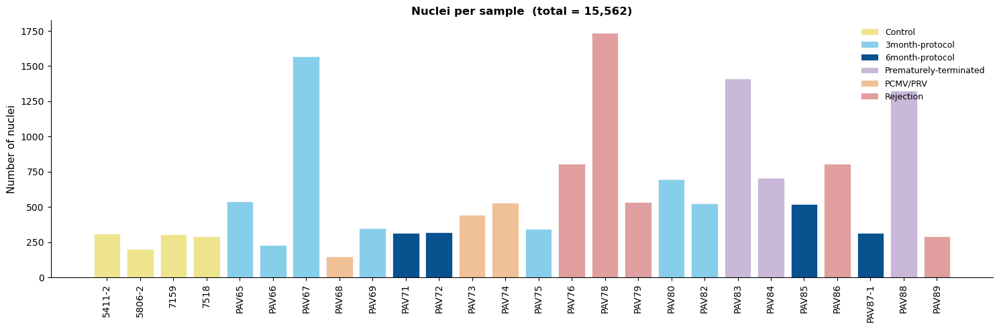

In [35]:
 
raw_FB = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/cleaned_raw_FB_v5.h5ad')

adata = raw_FB.copy()
 
print(f"Loaded: {adata.n_obs:,} nuclei  ×  {adata.n_vars:,} genes")
print(f"Conditions: {adata.obs['Condition'].value_counts().to_dict()}")
 
# Cell count bar plot per sample
sample_meta = adata.obs[["Sample_ID", "Condition"]].drop_duplicates().set_index("Sample_ID")
counts      = adata.obs["Sample_ID"].value_counts().sort_index()
bar_colors  = [COND_COLORS.get(sample_meta.loc[s, "Condition"], "grey") for s in counts.index]
 
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(range(len(counts)), counts.values, color=bar_colors, edgecolor="white", linewidth=0.5)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=10)
ax.set_ylabel("Number of nuclei", fontsize=11)
ax.set_title(f"Nuclei per sample  (total = {adata.n_obs:,})", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(facecolor=v, label=k) for k, v in COND_COLORS.items()],
    loc="upper right", frameon=False, fontsize=9
)
plt.tight_layout()
# plt.savefig(f"{OUTPUT_DIR}/01_cell_counts_per_sample.pdf", dpi=150, bbox_inches="tight")
plt.show()
# print("Saved: 01_cell_counts_per_sample")



In [36]:
counts

Sample_ID
5411-2      312
5806-2      201
7159        304
7518        289
PAV65       541
PAV66       231
PAV67      1567
PAV68       146
PAV69       348
PAV71       317
PAV72       319
PAV73       442
PAV74       529
PAV75       343
PAV76       805
PAV78      1738
PAV79       532
PAV80       698
PAV82       524
PAV83      1412
PAV84       705
PAV85       520
PAV86       807
PAV87-1     313
PAV88      1328
PAV89       291
Name: count, dtype: int64

# Preprocessing

In [37]:
raw_FB = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/cleaned_raw_FB_v5.h5ad')

adata = raw_FB.copy()
 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
 
# Store normalised + log-transformed counts for all genes.
# .raw is used later for differential expression (all genes, not just HVGs).
adata.raw = adata.copy()
print(f".raw stored: {adata.raw.shape[0]:,} nuclei × {adata.raw.shape[1]:,} genes")


.raw stored: 15,562 nuclei × 53,826 genes


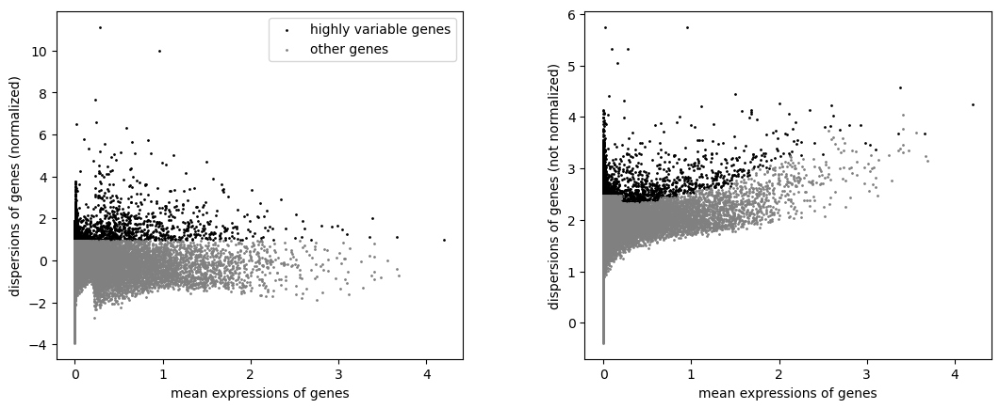

Number of highly variable genes (HVGs): 4000
Subsetting complete. New shape: (15562, 4000)


In [38]:
# 1. Identify highly variable genes 

sc.pp.highly_variable_genes(
    adata, 
    n_top_genes=4000, 
    subset=False, 
    flavor='seurat'
)

# 2. Plot highly variable genes
# This will highlight the top 5000 in red
sc.pl.highly_variable_genes(adata)

# 3. Verify the count
num_hvgs = adata.var['highly_variable'].sum()
print(f"Number of highly variable genes (HVGs): {num_hvgs}")

# 4. Subset to HVGs for downstream analysis (PCA/Harmony)
# We keep a copy of the full object if needed, but subset for speed
adata_hvg = adata[:, adata.var['highly_variable']].copy()

print(f"Subsetting complete. New shape: {adata_hvg.shape}")


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


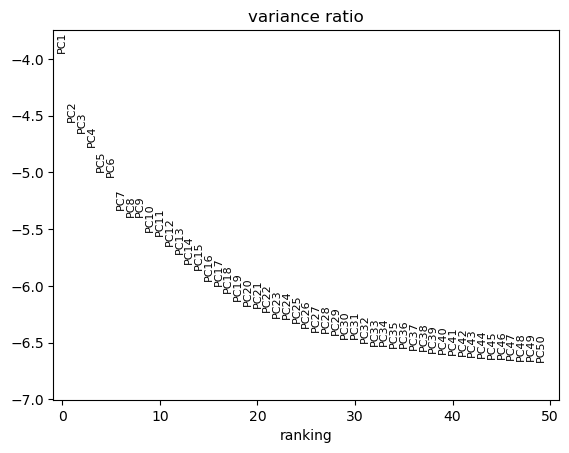

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [39]:
# 2. Scale the data (z-score normalization)
sc.pp.scale(adata_hvg, max_value=10)  # max_value=10 clips extreme outliers

# 3. Run PCA
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')  # Adjust n_comps as needed

# 4. (Optional) Plot variance explained
sc.pl.pca_variance_ratio(adata_hvg, log=True, n_pcs=50)

adata_hvg.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/FB_hvg_xeno_v5.h5ad')


In [40]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/FB_hvg_xeno_v5.h5ad')


# Harmony

In [41]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/FB_hvg_xeno_v5.h5ad')


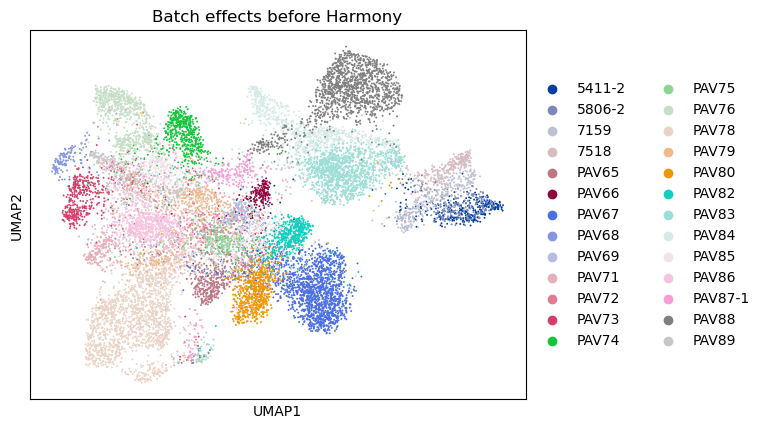

In [42]:
# Checking batch effects before Harmony
sc.pp.neighbors(pca_adata, random_state=10, n_neighbors=30, n_pcs=40)

# Perform UMAP
sc.tl.umap(pca_adata)

# Plot UMAP colored by sample (batch) and save it
sc.pl.umap (pca_adata, color=['Sample_ID'],  title='Batch effects before Harmony')

In [43]:
# Subset PCA to exactly the PCs used for neighbours
pca_matrix = pca_adata.obsm["X_pca"][:, :40].copy()
print(f"PCA matrix passed to Harmony: {pca_matrix.shape}")

ho = hm.run_harmony(
    pca_matrix,
    pca_adata.obs,
    vars_use="Sample_ID",
    # max_iter_harmony=10,
    epsilon_harmony=-float('Inf'), # FORCE RUN: Ignore early convergence
    epsilon_cluster=-float('Inf'), # FORCE RUN: Ignore early convergence
    
    random_state=10,
    verbose=True         # Prints iteration + objective value so you can
                         # see exactly when and why it stops
)
 
pca_adata.obsm["X_pca_harmony"] = ho.Z_corr.T
 
print(f"\nHarmony embedding stored in obsm['X_pca_harmony']")
print(f"Shape: {pca_adata.obsm['X_pca_harmony'].shape}") 
 

2026-06-29 16:40:35,795 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


PCA matrix passed to Harmony: (15562, 40)


2026-06-29 16:40:37,539 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-06-29 16:40:37,583 - harmonypy - INFO - Iteration 1 of 10
2026-06-29 16:40:40,338 - harmonypy - INFO - Iteration 2 of 10
2026-06-29 16:40:43,060 - harmonypy - INFO - Iteration 3 of 10
2026-06-29 16:40:45,723 - harmonypy - INFO - Iteration 4 of 10
2026-06-29 16:40:48,397 - harmonypy - INFO - Iteration 5 of 10
2026-06-29 16:40:51,057 - harmonypy - INFO - Iteration 6 of 10
2026-06-29 16:40:53,734 - harmonypy - INFO - Iteration 7 of 10
2026-06-29 16:40:56,396 - harmonypy - INFO - Iteration 8 of 10
2026-06-29 16:40:59,077 - harmonypy - INFO - Iteration 9 of 10
2026-06-29 16:41:01,740 - harmonypy - INFO - Iteration 10 of 10
2026-06-29 16:41:04,411 - harmonypy - INFO - Stopped before convergence



Harmony embedding stored in obsm['X_pca_harmony']
Shape: (15562, 40)


In [44]:
pca_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/hm_FB_hvg_xeno_v5.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [38]:
hm_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/hm_FB_hvg_xeno_v5.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


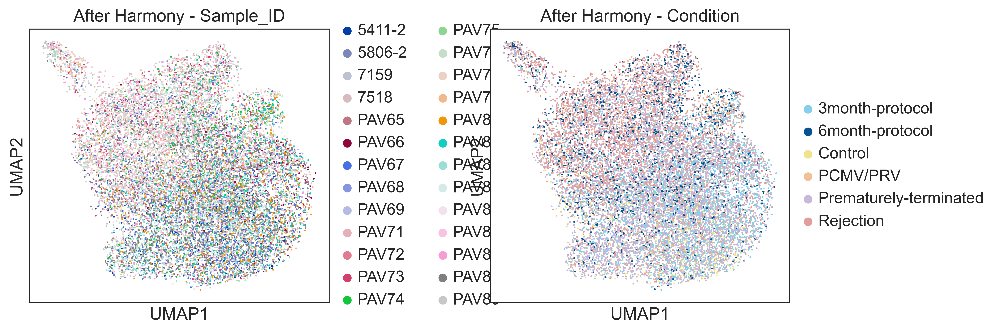

In [39]:
# Compute neighbors using Harmony embeddings
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony',
    n_neighbors=30, 
    n_pcs=40,
    random_state=10
)

# Recompute UMAP based on Harmony
sc.tl.umap(hm_adata, random_state=10)

# Visualize - should show reduced batch effects
sc.pl.umap(
    hm_adata, color=['Sample_ID', 'Condition'],  ncols=2, wspace = 0.4,  title=['After Harmony - Sample_ID', 'After Harmony - Condition']
)

In [40]:
# 1. Compute Neighbors (Graph building)
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony', 
    n_neighbors=35, 
    n_pcs=40,
    random_state=10
)

# 2. Run UMAP with min_dist and spread (Embedding/Visualization)
sc.tl.umap(
    hm_adata, 
    min_dist=0.4, 
    spread=1, 
    random_state=10
)

# 3. Run Leiden Clustering (Community detection)
resolutions = [
    0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1 
              ]

for res in resolutions:
    # Formats key cleanly (e.g., leiden_03, leiden_04)
    key = f"leiden_{str(res).replace('.', '')}"
    print(f"Running Leiden clustering at resolution {res} -> stored in {key}")
    
    sc.tl.leiden(
        hm_adata, 
        resolution=res, 
        key_added=key, 
        random_state=10
    )

print("✓ UMAP and Leiden clustering complete.")

Running Leiden clustering at resolution 0.4 -> stored in leiden_04


/tmp/ipykernel_896905/2629939855.py:28: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Running Leiden clustering at resolution 0.5 -> stored in leiden_05
Running Leiden clustering at resolution 0.6 -> stored in leiden_06
Running Leiden clustering at resolution 0.7 -> stored in leiden_07
Running Leiden clustering at resolution 0.8 -> stored in leiden_08
Running Leiden clustering at resolution 0.9 -> stored in leiden_09
Running Leiden clustering at resolution 1.0 -> stored in leiden_10
Running Leiden clustering at resolution 1.1 -> stored in leiden_11
✓ UMAP and Leiden clustering complete.


In [41]:

sc.pl.umap( hm_adata, color=[  "leiden_04", "leiden_05" , "leiden_06" , "leiden_07", "leiden_08" , "leiden_09", "leiden_10", "leiden_11", 'Sus_scrofa___POSTN' ],
            legend_loc="on data",  
           cmap = dimplot_color,
           size=15)


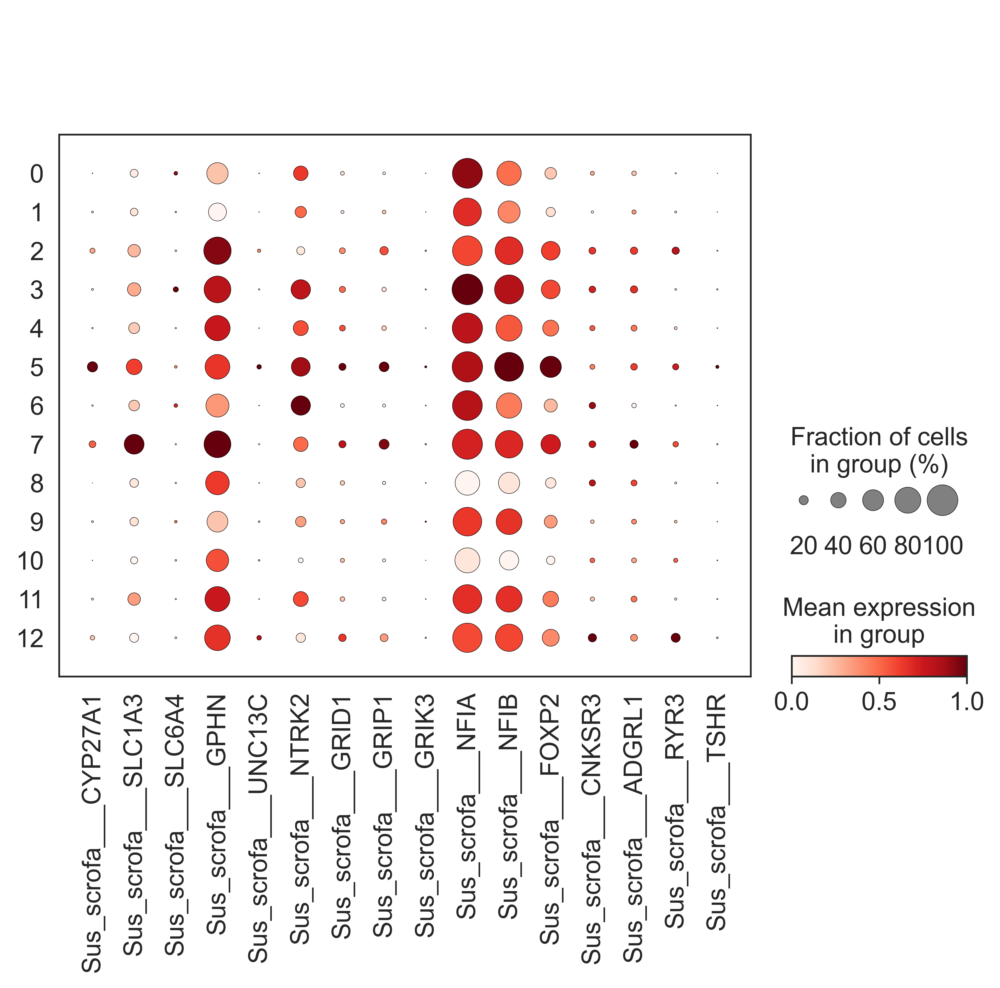

In [49]:
sc.pl.dotplot(
    hm_adata, 
    var_names=[


'Sus_scrofa___CYP27A1',
        'Sus_scrofa___SLC1A3',
        'Sus_scrofa___SLC6A4',
        'Sus_scrofa___GPHN',
        'Sus_scrofa___UNC13C',
 'Sus_scrofa___NTRK2',
 'Sus_scrofa___GRID1', 'Sus_scrofa___GRIP1',
         'Sus_scrofa___GRIK3',
        'Sus_scrofa___NFIA', 'Sus_scrofa___NFIB',
 'Sus_scrofa___FOXP2',
         'Sus_scrofa___CNKSR3',
        'Sus_scrofa___ADGRL1',       'Sus_scrofa___RYR3',
        'Sus_scrofa___TSHR',


        
    ], 
    groupby='leiden_11', 
    # standard_scale='var', 
    cmap='Reds', 
    standard_scale = 'var',
    use_raw = True

)
    

In [51]:
import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS & SETTINGS
# ---------------------------
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/"
os.makedirs(RESULTS_DIR, exist_ok=True)

CLUSTER_ID = '5'
CLUSTERING_KEY = 'leiden_11'  # <-- Change this if your clusters are under leiden_08, leiden_12, etc.
N_GENES = 500

# ---------------------------
# 1. CHECK AND RECALCULATE DEA
# ---------------------------
if 'wilcoxon' not in hm_adata.uns:
    print(f"⚠️ 'wilcoxon' results not found in object.")
    print(f"Recalculating marker genes for '{CLUSTERING_KEY}' using Wilcoxon test (this may take a minute)...")
    
    # Recalculate using the raw data (standard practice for DEA)
    sc.tl.rank_genes_groups(
        hm_adata, 
        groupby=CLUSTERING_KEY, 
        method='wilcoxon', 
        key_added='wilcoxon', 
        use_raw=True
    )
    print("✓ DEA Recalculation complete.")
else:
    print("✓ 'wilcoxon' DEA results found in object.")

# ---------------------------
# 2. EXTRACT MARKERS
# ---------------------------
try:
    # Extract the DEA results specifically for cluster 3
    cluster_df = sc.get.rank_genes_groups_df(hm_adata, group=CLUSTER_ID, key='wilcoxon')

    # Sort by the highest score (most significant/expressed) and isolate the top 350 genes
    top_genes_df = cluster_df.sort_values(by='scores', ascending=False).head(N_GENES)

    # ---------------------------
    # 3. SAVE TO CSV
    # ---------------------------
    out_csv = os.path.join(RESULTS_DIR, f"Cluster_{CLUSTER_ID}_top{N_GENES}_markers.csv")
    
    # Save the dataframe without the pandas index column for a cleaner file
    top_genes_df.to_csv(out_csv, index=False)

    print(f"\n✓ Successfully extracted {len(top_genes_df)} markers for Cluster {CLUSTER_ID}.")
    print(f"Saved to: {out_csv}")

except Exception as e:
    print(f"\n❌ Error extracting cluster '{CLUSTER_ID}': {e}")

✓ 'wilcoxon' DEA results found in object.

✓ Successfully extracted 500 markers for Cluster 5.
Saved to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/Cluster_5_top500_markers.csv


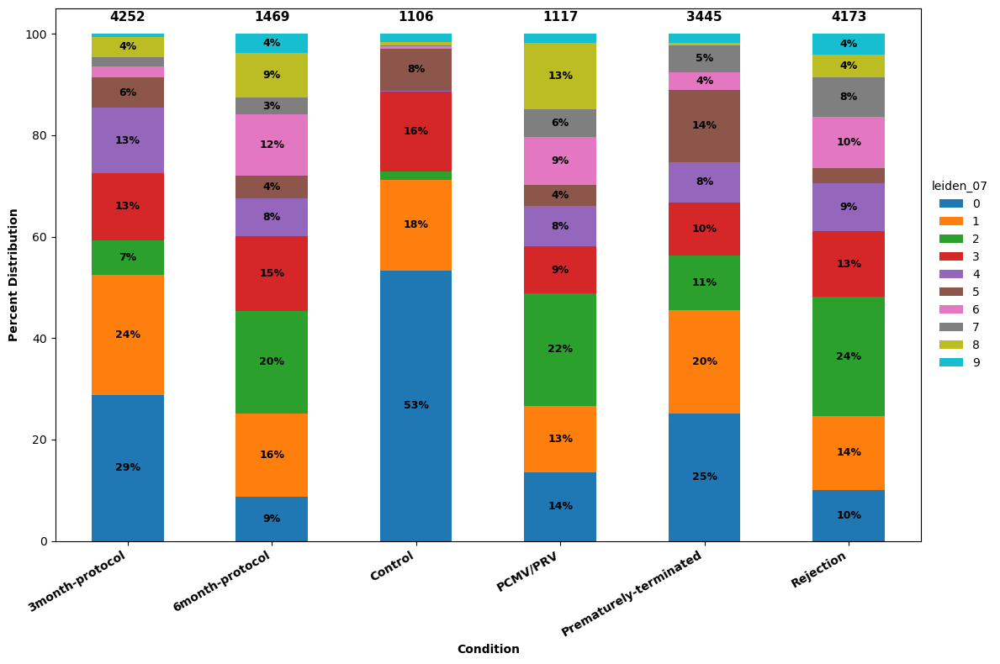

In [106]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    # Ensure the order of bars matches the state_order defined in your categorical data
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    hm_adata, 
    xaxis='Condition', 
    stack='leiden_07', 
    xaxis_label='Condition', 
    legend_label='leiden_07', 
    xaxis_rotation=30, 
    figsize=(12, 8), 
    percent=True
)

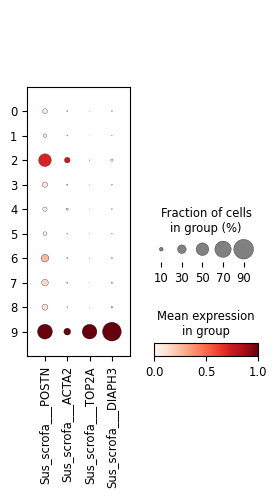

In [105]:
sc.pl.dotplot(
    hm_adata, 
    var_names=[
'Sus_scrofa___POSTN',
'Sus_scrofa___ACTA2',
        'Sus_scrofa___TOP2A',
'Sus_scrofa___DIAPH3',

        
# 'Sus_scrofa___FBN1',
# 'Sus_scrofa___GSN',
# 'Sus_scrofa___CREB5',
# 'Sus_scrofa___GFPT2',
# 'Sus_scrofa___DDR2',
# 'Sus_scrofa___ABI3BP',
# 'Sus_scrofa___SOX5',
# 'Sus_scrofa___FMNL2',
# 'Sus_scrofa___VCAN',

# 'Sus_scrofa___ABCA6',
# 'Sus_scrofa___MAML2',
# 'Sus_scrofa___PLPP4',
# 'Sus_scrofa___LAMC1',
# 'Sus_scrofa___CCBE1',
# 'Sus_scrofa___PID1',
# 'Sus_scrofa___RIPOR3',
# 'Sus_scrofa___NFIA',
# 'Sus_scrofa___EBF1',
# 'Sus_scrofa___RORA',
# 'Sus_scrofa___HMCN2',
# 'Sus_scrofa___PLXDC2',
# 'Sus_scrofa___ABCA8',
# 'Sus_scrofa___BICC1'


        
    ], 
    groupby='leiden_07', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    use_raw = True

)
    

# DEA

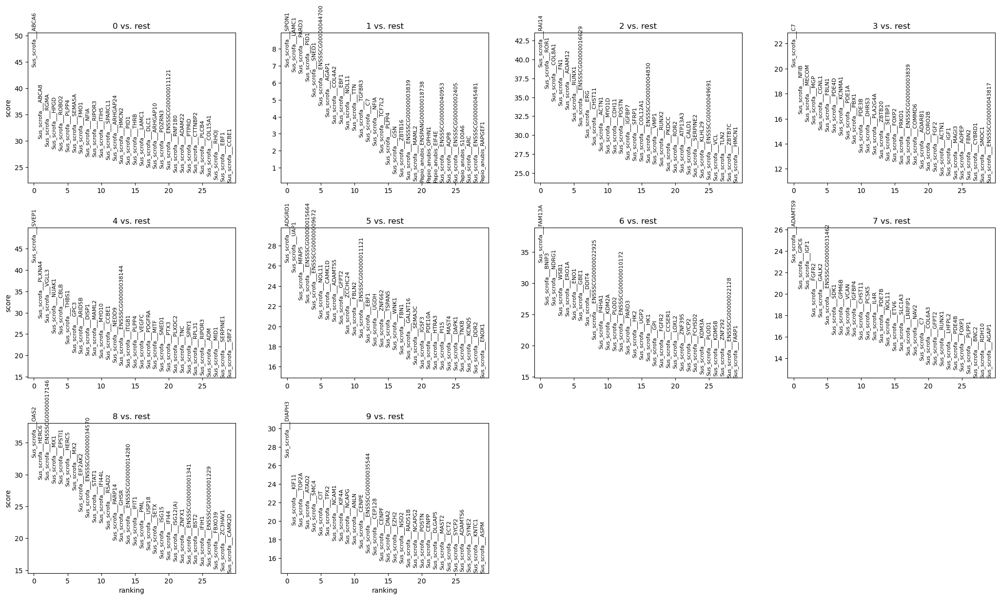

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [107]:
# Perform differential expression to find marker genes for each cluster using Wilcoxon test on raw data
sc.tl.rank_genes_groups(hm_adata, 'leiden_07', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(hm_adata, key='wilcoxon', n_genes=30, sharey=False)

hm_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_FB_xeno_v5.h5ad')


In [10]:
dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_FB_xeno_v5.h5ad')


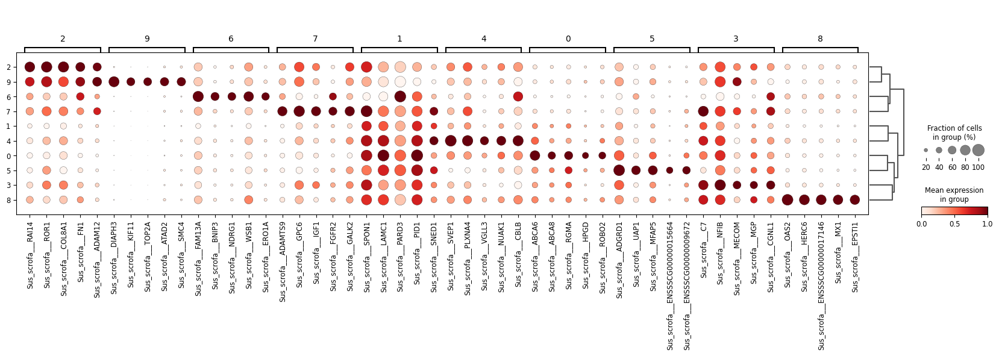

In [109]:
%matplotlib inline
sc.pl.rank_genes_groups_dotplot(dea_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


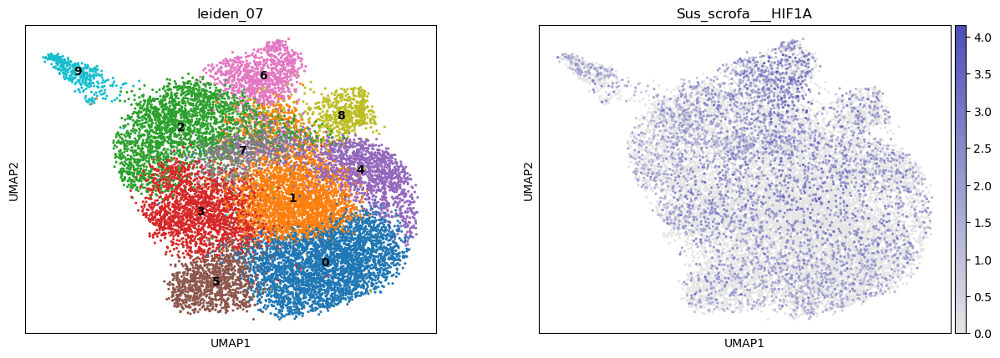

In [110]:

sc.pl.umap( dea_adata, color=[  "leiden_07", "Sus_scrofa___HIF1A" ], cmap = dimplot_color,
            legend_loc="on data",  size=20)


In [111]:
import pandas as pd
import os

de_key = 'wilcoxon' 
results = dea_adata.uns[de_key]
clusters = results['names'].dtype.names 

output_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/DEGs'
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [112]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/DEGs'
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.5

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.5
  Cluster 0: Saved 721 significant DEGs.
  Cluster 1: Saved 4707 significant DEGs.
  Cluster 2: Saved 1823 significant DEGs.
  Cluster 3: Saved 265 significant DEGs.
  Cluster 4: Saved 427 significant DEGs.
  Cluster 5: Saved 565 significant DEGs.
  Cluster 6: Saved 863 significant DEGs.
  Cluster 7: Saved 519 significant DEGs.
  Cluster 8: Saved 277 significant DEGs.
  Cluster 9: Saved 1795 significant DEGs.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/DEGs/significant_DEGs


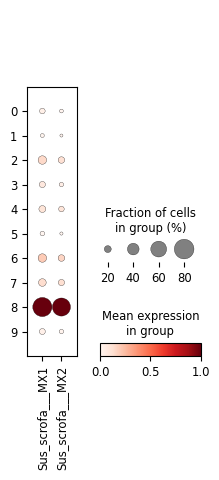

In [119]:
sc.pl.dotplot(
    dea_adata, 
    var_names=[

# 'Sus_scrofa___HIF1A',
#         'Sus_scrofa___ERO1A',

        # 'Sus_scrofa___MX1',
        # 'Sus_scrofa___MX2',
        
# VFB3
# 'Sus_scrofa___NR4A1',
# 'Sus_scrofa___JUNB',
# 'Sus_scrofa___FOS',
# 'Sus_scrofa___STAT3',
# 'Sus_scrofa___NAMPT',
# 'Sus_scrofa___EGR1',
# 'Sus_scrofa___ZFP36',
# 'Sus_scrofa___B4GALT1',
# 'Sus_scrofa___ELL2',
# 'Sus_scrofa___GADD45B',
# 'Sus_scrofa___KAZN',
# 'Sus_scrofa___SOCS3',
# 'Sus_scrofa___DUSP1',
# 'Sus_scrofa___LITAF',
# 'Sus_scrofa___THBS1',
# 'Sus_scrofa___SLC19A2',
# 'Sus_scrofa___CHD1',
# 'Sus_scrofa___SAT1',
# 'Sus_scrofa___PDE4D',
# 'Sus_scrofa___LMNA',
# 'Sus_scrofa___ADAMTS4',
# 'Sus_scrofa___GFPT2',
# 'Sus_scrofa___VMP1',
# 'Sus_scrofa___CRISPLD2',
# 'Sus_scrofa___IGFBP4',
# 'Sus_scrofa___SH3BP5'

# VFB4
# 'Sus_scrofa___MFAP5', 'Sus_scrofa___CD248',
# 'Sus_scrofa___UAP1',
# 'Sus_scrofa___FBN1',
# 'Sus_scrofa___GSN',
# 'Sus_scrofa___CREB5',
# 'Sus_scrofa___GFPT2',
# 'Sus_scrofa___DDR2',
# 'Sus_scrofa___ABI3BP',
# 'Sus_scrofa___SOX5',
# 'Sus_scrofa___FMNL2',
# 'Sus_scrofa___VCAN',
# 'Sus_scrofa___DOCK4',
# 'Sus_scrofa___ABLIM1',
# 'Sus_scrofa___ACKR3'



# Homeo_vFB1

# 'Sus_scrofa___ABCA6',
# 'Sus_scrofa___MAML2',
# 'Sus_scrofa___PLPP4',
# 'Sus_scrofa___LAMC1',
# 'Sus_scrofa___CCBE1',
# 'Sus_scrofa___PID1',
# 'Sus_scrofa___RIPOR3',
# 'Sus_scrofa___NFIA',
# 'Sus_scrofa___EBF1',
# 'Sus_scrofa___RORA',
# 'Sus_scrofa___HMCN2',
# 'Sus_scrofa___PLXDC2',
# 'Sus_scrofa___ABCA8',
# 'Sus_scrofa___BICC1'


'Sus_scrofa___KCND3',
'Sus_scrofa___TMEM132C',
'Sus_scrofa___SLC39A8',
'Sus_scrofa___NTRK3',
'Sus_scrofa___PRTG',
'Sus_scrofa___NR2F2',
'Sus_scrofa___C3',
'Sus_scrofa___GRK3',
'Sus_scrofa___C7',
'Sus_scrofa___CPED1',
'Sus_scrofa___C4A',
'Sus_scrofa___ANKS1B',
'Sus_scrofa___THSD4',

        
    ], 
    groupby='leiden_07', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    use_raw = True

)
    

/tmp/ipykernel_2481744/3920788969.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_means = mean_expr.groupby(cluster_key).mean()


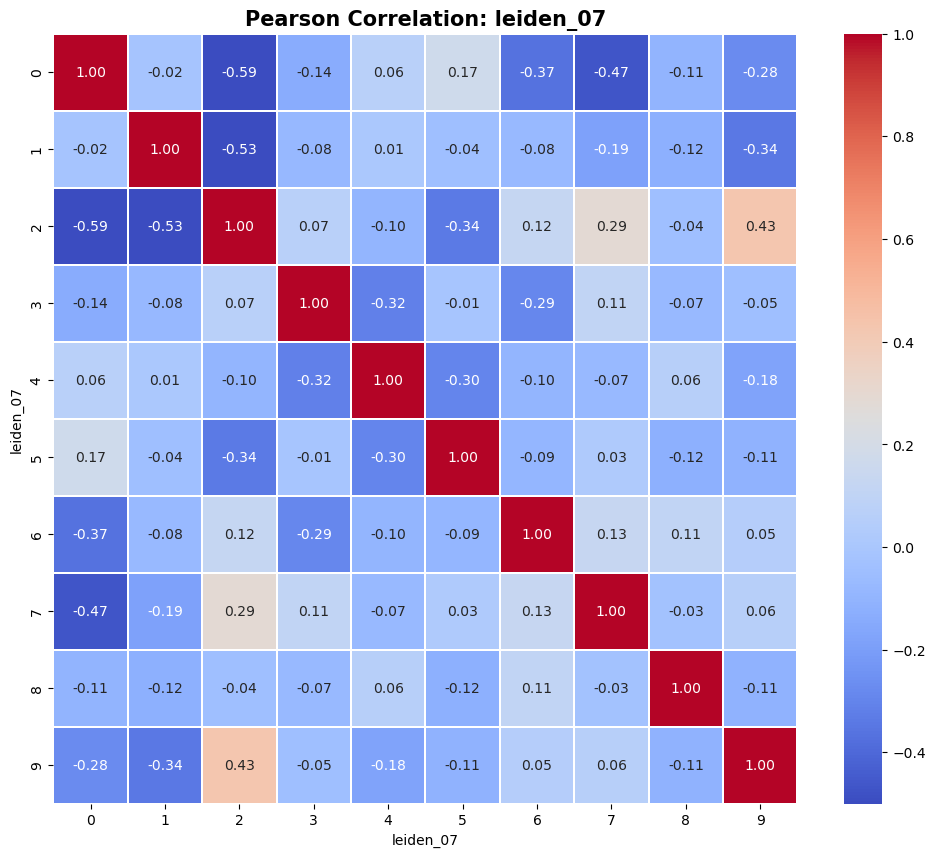

In [121]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_cluster_correlation(adata, cluster_key):
    # 1. Calculate the mean expression for each gene in each cluster
    # .to_df() makes it easier to group
    mean_expr = pd.DataFrame(
        adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X,
        index=adata.obs_names,
        columns=adata.var_names
    )
    mean_expr[cluster_key] = adata.obs[cluster_key].values
    
    # Group by cluster and calculate mean
    cluster_means = mean_expr.groupby(cluster_key).mean()
    
    # 2. Calculate Pearson Correlation
    # Transpose so we correlate clusters (columns), not genes
    corr_matrix = cluster_means.T.corr(method='pearson')
    
    # 3. Plot Heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        corr_matrix, 
        annot=True, 
        fmt=".2f", 
        cmap='coolwarm', 
        vmin=-0.5, vmax=1, # Focus on high correlations
        linewidths=0.3
    )
    plt.title(f'Pearson Correlation: {cluster_key}', fontsize=15, fontweight='bold')
    plt.show()

# Run for leiden_05
plot_cluster_correlation(dea_adata, 'leiden_07')

# Annotation

In [9]:
dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_FB_xeno_v5.h5ad')


In [10]:
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=300, dpi_save=300)
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42


# ---------------------------
# PATHS
# ---------------------------
# Updated to reflect the Fibroblast (Fb) lineage
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results"
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(OBJECTS_DIR, exist_ok=True)

sc.settings.figdir = RESULTS_DIR
sc.settings.autosave = False
sc.settings.set_figure_params(dpi=300)


# ---------------------------
# ANNOTATION
# ---------------------------
cluster_annotation = {
    '0': 'Homeo_FB',
    '1': 'Homeo_FB',
    '2': 'Myo_FB',
    '3': 'ECM_FB',
    '4': 'Angio_FB',
    '5': 'Progenitor_FB',
    '6': 'Hypoxia_FB',
    '7': 'Myo_FB',
    '8': 'ISG_FB',
    '9': 'Prolif_Myo_FB'
}

# Ensure the new cluster column is treated as a string
dea_adata.obs['leiden_07'] = dea_adata.obs['leiden_07'].astype(str)

# Map annotations to the new cell_state column
dea_adata.obs['cell_state'] = dea_adata.obs['leiden_07'].map(cluster_annotation)

# Safety check for unmapped cells
n_missing = dea_adata.obs['cell_state'].isna().sum()
print(f"cell_state missing (NaN) for {n_missing} cells")

# ---------------------------
# CATEGORICAL ORDERING
# ---------------------------
# Logical biological progression for the cardiac stroma
state_order = [
    'Homeo_FB',
    'Progenitor_FB',
    'Angio_FB',
    'ECM_FB',
    'Myo_FB',
    'Hypoxia_FB',
    'ISG_FB',
    'Prolif_Myo_FB'
]

present_states = [s for s in state_order if s in dea_adata.obs["cell_state"].unique()]

dea_adata.obs["cell_state"] = pd.Categorical(
    dea_adata.obs["cell_state"],
    categories=present_states,
    ordered=True
)

# ---------------------------
# COLORS
# ---------------------------
# Distinct palette suited for stromal states
cell_state_colors = {
    "Homeo_FB":      "#4682B4", # Muted Blue (Resting)
    "Progenitor_FB":           "#F1C40F", # Yellow (Progenitor/Adventitial)
    "Angio_FB":      "#27AE60", # Green (Paracrine/Supportive)
    "ECM_FB":        "#F8BBD0", # Purple (Matrix Remodeling)
    "Myo_FB":        "#E74C3C", # Coral/Red (Activated/Contractile)
    "Hypoxia_FB":    "#8E44AD", # Purple (Stressed/Ischemic)
    "ISG_FB":        "#E67E22", # Orange (Interferon/Inflammatory)
    "Prolif_Myo_FB": "#7F8C8D"  # Pink (Dividing)
}

# Ensure categories align with the color dictionary
dea_adata.uns["cell_state_colors"] = [
    cell_state_colors[s] for s in dea_adata.obs["cell_state"].cat.categories
]

# ---------------------------
# PLOTS
# ---------------------------
plot_kwargs = dict(
    frameon=False,
    size=10,
    alpha=0.7,
    legend_loc="on data",
    legend_fontsize=7,
    legend_fontweight="bold",
    legend_fontoutline=1,
)

with plt.rc_context({"figure.figsize": (5, 3)}):
    sc.pl.umap(
        dea_adata,
        color=["cell_state"],
        **plot_kwargs,
        save="_Annotated_Fb_sus_v1_UMAP.pdf",
        show=False
    )

# ---------------------------
# SAVE
# ---------------------------
out_h5ad = os.path.join(OBJECTS_DIR, "Annotated_Fb_sus_v1.h5ad")
dea_adata.write(out_h5ad)
print(f"\nSaved annotated object to: {out_h5ad}")


cell_state missing (NaN) for 0 cells


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)



Saved annotated object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Fb_sus_v1.h5ad


In [26]:
annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Fb_sus_v1.h5ad')

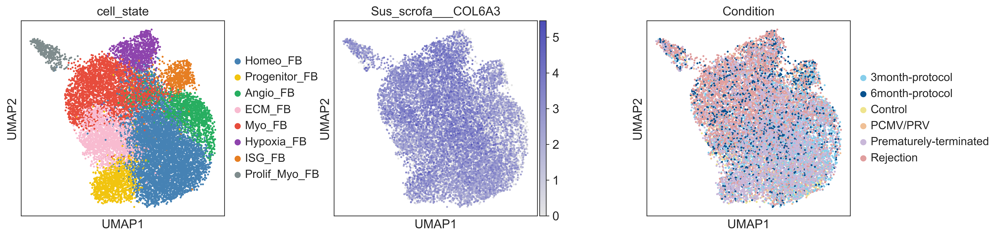

In [30]:

sc.pl.umap( annotated_adata, color=[  "cell_state", 'Sus_scrofa___COL6A3', "Condition" ], cmap = dimplot_color,
            legend_loc="right margin", wspace = 0.4, size=20)


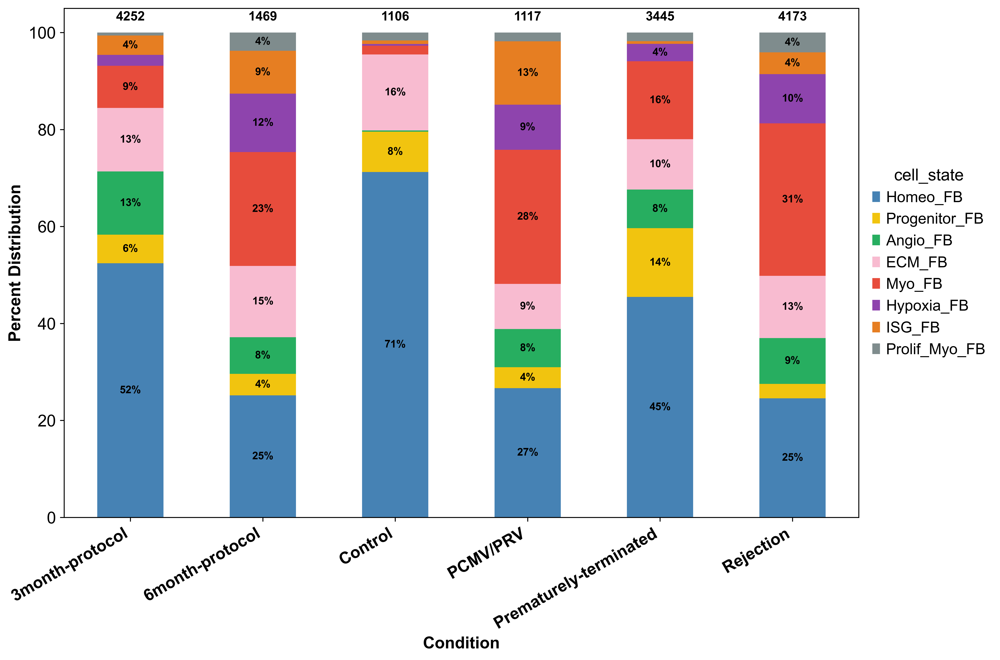

In [6]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    annotated_adata, 
    xaxis='Condition', 
    stack='cell_state', 
    xaxis_label='Condition', 
    legend_label='cell_state', 
    xaxis_rotation=30, 
    figsize=(12, 8), 
    percent=True
)

/tmp/ipykernel_896905/3883080034.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_means = mean_expr.groupby(cluster_key).mean()


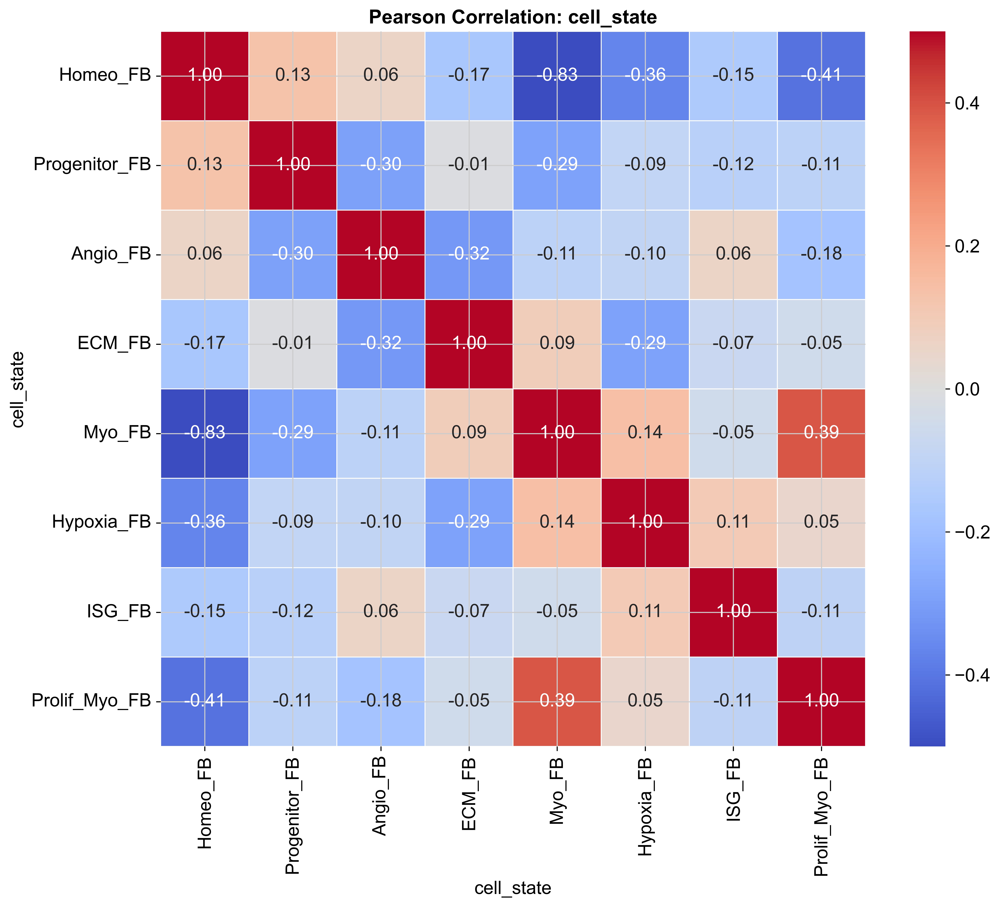

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_cluster_correlation(adata, cluster_key):
    # 1. Calculate the mean expression for each gene in each cluster
    # We use .raw.X if you want log-normalized data, or adata.X depending on your setup
    # .to_df() makes it easier to group
    mean_expr = pd.DataFrame(
        adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X,
        index=adata.obs_names,
        columns=adata.var_names
    )
    mean_expr[cluster_key] = adata.obs[cluster_key].values
    
    # Group by cluster and calculate mean
    cluster_means = mean_expr.groupby(cluster_key).mean()
    
    # 2. Calculate Pearson Correlation
    # Transpose so we correlate clusters (columns), not genes
    corr_matrix = cluster_means.T.corr(method='pearson')
    
    # 3. Plot Heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        corr_matrix, 
        annot=True, 
        fmt=".2f", 
        cmap='coolwarm', 
        vmin=-0.5, vmax=0.5, # Focus on high correlations
        linewidths=0.5
    )
    plt.title(f'Pearson Correlation: {cluster_key}', fontsize=15, fontweight='bold')
    plt.show()

# Run for leiden_05
plot_cluster_correlation(annotated_adata, 'cell_state')

# Annotated DEA

In [8]:
annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Fb_sus_v1.h5ad')

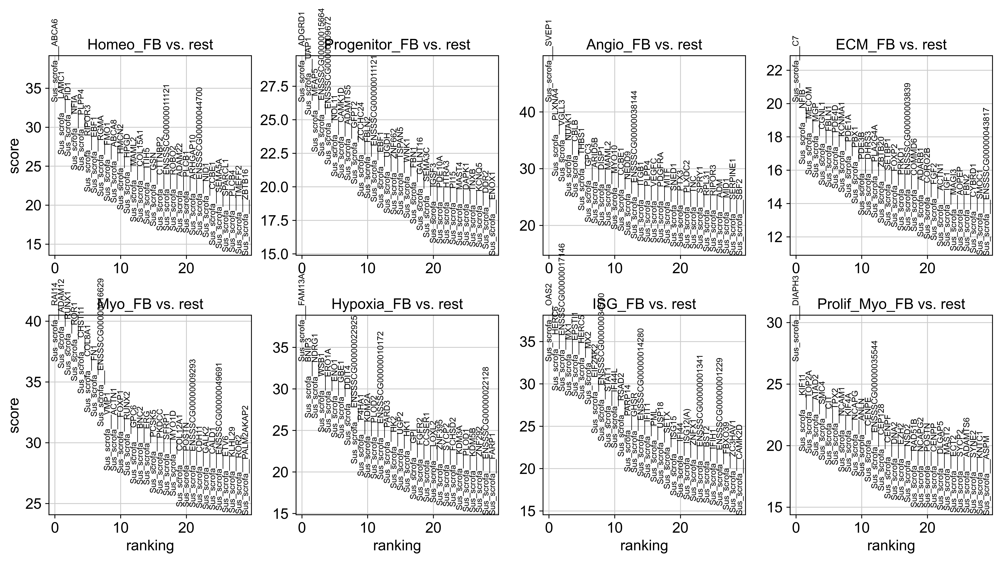

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [9]:

# Perform differential expressxion to find marker genes for each cluster using Wilcoxon test on raw data
sc.tl.rank_genes_groups(annotated_adata, 'cell_state', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(annotated_adata, key='wilcoxon', n_genes=30, sharey=False)

# Save the DE analysis to an H5AD file
annotated_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_annotated_FB_v3.h5ad')


In [2]:
dea_annotated_FB = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_annotated_FB_v3.h5ad')


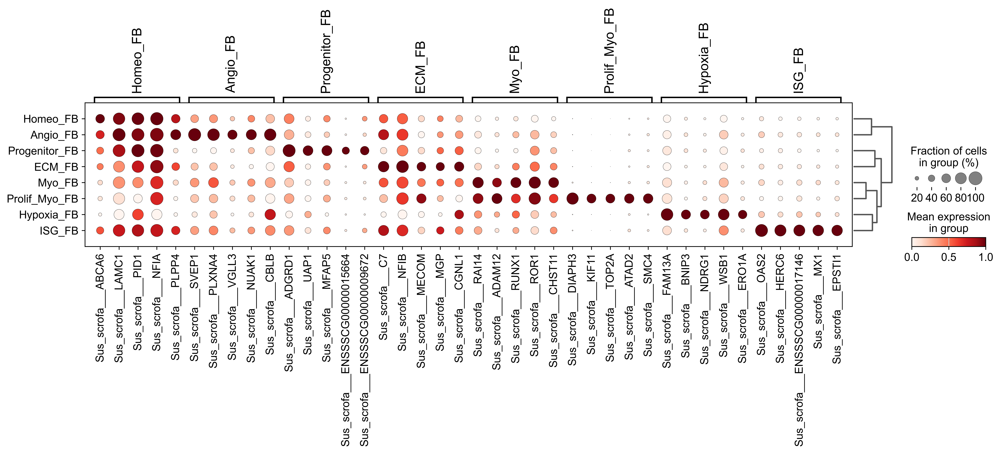

In [11]:
%matplotlib inline

sc.pl.rank_genes_groups_dotplot(dea_annotated_FB, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


In [12]:
import pandas as pd
import os

de_key = 'wilcoxon' 
results = dea_annotated_FB.uns[de_key]
clusters = results['names'].dtype.names  

output_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/Annotated_DEGs"
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [13]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/Annotated_DEGs"
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.75

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.75
  Cluster Homeo_FB: Saved 775 significant DEGs.
  Cluster Progenitor_FB: Saved 388 significant DEGs.
  Cluster Angio_FB: Saved 233 significant DEGs.
  Cluster ECM_FB: Saved 146 significant DEGs.
  Cluster Myo_FB: Saved 788 significant DEGs.
  Cluster Hypoxia_FB: Saved 607 significant DEGs.
  Cluster ISG_FB: Saved 197 significant DEGs.
  Cluster Prolif_Myo_FB: Saved 1274 significant DEGs.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/Annotated_DEGs/significant_DEGs


In [37]:
dea_annotated_FB = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_annotated_FB_v3.h5ad')

import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS
# ---------------------------
# Update this to wherever you want the CSV saved!
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/Annotated_DEGs"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---------------------------
# EXTRACT MARKERS
# ---------------------------
cluster_id = 'ECM_FB'

try:
    # IMPORTANT FIX: Added key='wilcoxon' to match your sc.tl.rank_genes_groups command
    cluster_5_df = sc.get.rank_genes_groups_df(dea_annotated_FB, group=cluster_id, key='wilcoxon')

    # Sort by the highest score (most significant/expressed) and isolate the top 300 genes
    top_300_df = cluster_5_df.sort_values(by='scores', ascending=False).head(300)

    # ---------------------------
    # SAVE TO CSV
    # ---------------------------
    out_csv = os.path.join(RESULTS_DIR, f"Cluster_{cluster_id}_ECM_FB_top300_markers.csv")
    
    # Save the dataframe without the pandas index column for a cleaner file
    top_300_df.to_csv(out_csv, index=False)

    print(f"\n✓ Successfully extracted {len(top_300_df)} markers for Cluster {cluster_id}.")
    print(f"Saved to: {out_csv}")

except KeyError as e:
    print(f"\n❌ Error: Could not find the expected data. Details: {e}")
except ValueError as e:
    print(f"\n❌ Error extracting cluster '{cluster_id}': {e}")


✓ Successfully extracted 300 markers for Cluster ECM_FB.
Saved to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/results/Annotated_DEGs/Cluster_ECM_FB_ECM_FB_top300_markers.csv


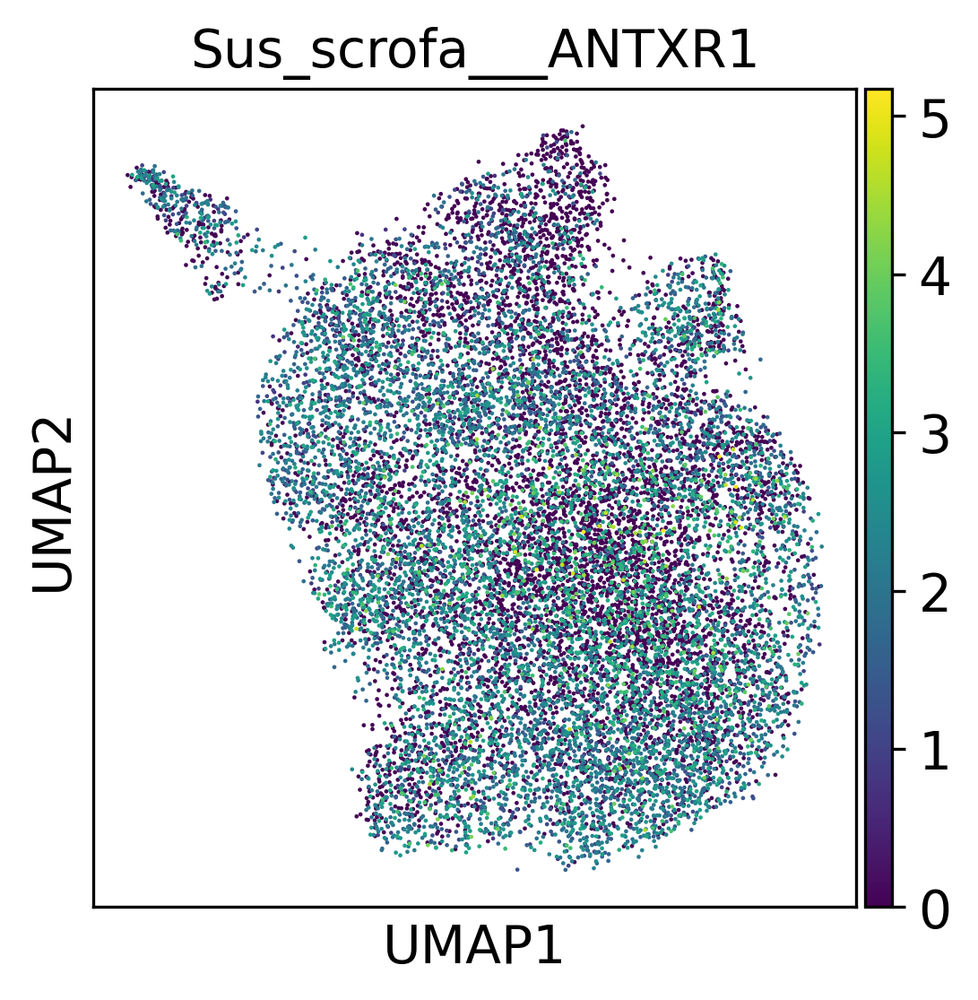

In [4]:
# --- 3. CREATE CUSTOM COLORMAP ---

sc.pl.umap(
    dea_annotated_FB, 
    color="Sus_scrofa___ANTXR1", 
 # cmap=dimplot_color,
    size=5,
    legend_loc="right margin"
)

# New label transfer

In [5]:
import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS
# ---------------------------
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects"

annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/dea_annotated_FB_v3.h5ad')

raw_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/cleaned_raw_FB_v5.h5ad')

SAVE_PATH = os.path.join(OBJECTS_DIR, "Annotated_Raw_FB_preclinical_xeno_v1.h5ad")

print(f"Annotated cells: {annotated_adata.n_obs}")
print(f"Raw cells: {raw_adata.n_obs}")

# ---------------------------
# LABEL TRANSFER
# ---------------------------
# Create a mapping series from the annotated object
label_map = annotated_adata.obs['cell_state']

# Map these to the raw object (this ensures cells align by index)
raw_adata.obs['cell_state'] = raw_adata.obs_names.map(label_map)

# ---------------------------
# UNS TRANSFER
# ---------------------------
# Transfer the color dictionary
if 'cell_state_colors' in annotated_adata.uns:
    raw_adata.uns['cell_state_colors'] = annotated_adata.uns['cell_state_colors']
    print("Transferred cell_state_colors to raw object.")

# ---------------------------
# VALIDATION & FILTERING
# ---------------------------
n_missing = raw_adata.obs['cell_state'].isna().sum()
if n_missing > 0:
    print(f"WARNING: {n_missing} cells in the raw object could not be mapped. Removing them...")
    # Filter out any cells that have NaN in the cell_state column
    raw_adata = raw_adata[raw_adata.obs['cell_state'].notna()].copy()
    print(f"Cells remaining after filter: {raw_adata.n_obs}")
else:
    print("All cells successfully mapped.")

# ---------------------------
# UMAP TRANSFER
# ---------------------------
# We align the UMAP matrix by cell barcodes to ensure perfect mathematical alignment
if 'X_umap' in annotated_adata.obsm:
    # Convert annotated UMAP to a DataFrame indexed by cell barcodes
    umap_df = pd.DataFrame(
        annotated_adata.obsm['X_umap'], 
        index=annotated_adata.obs_names
    )
    
    # Slice the dataframe to match the exact order and composition of the filtered raw object
    aligned_umap = umap_df.loc[raw_adata.obs_names].values
    
    # Assign it safely to the raw object's .obsm
    raw_adata.obsm['X_umap'] = aligned_umap
    print("Transferred UMAP coordinates to raw object.")
else:
    print("WARNING: 'X_umap' not found in annotated_adata.obsm. Skipping UMAP transfer.")

# ---------------------------
# SAVE
# ---------------------------
raw_adata.write(SAVE_PATH)
print(f"\nSaved annotated raw object to: {SAVE_PATH}")

Annotated cells: 15562
Raw cells: 15562
Transferred cell_state_colors to raw object.
All cells successfully mapped.
Transferred UMAP coordinates to raw object.

Saved annotated raw object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Raw_FB_preclinical_xeno_v1.h5ad


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [8]:
raw_annotated_FB = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Raw_FB_preclinical_xeno_v1.h5ad')

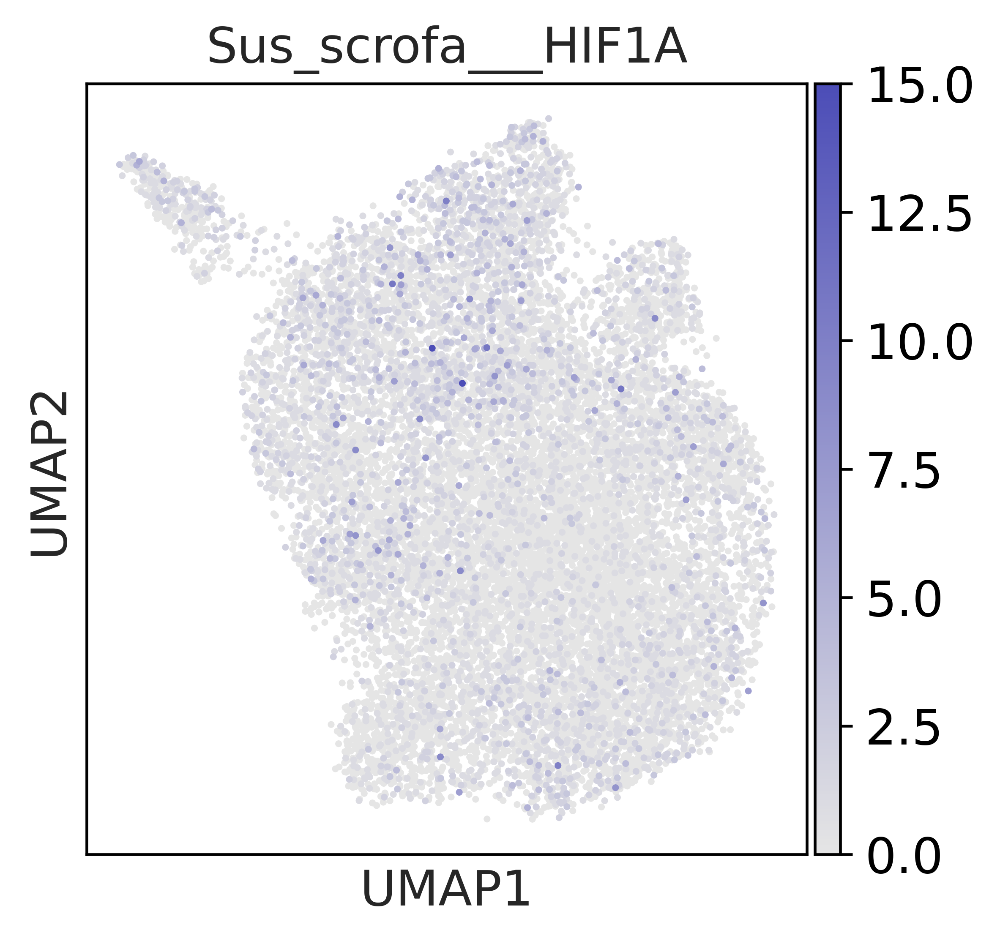

In [13]:
# --- 3. CREATE CUSTOM COLORMAP ---

sc.pl.umap(
    raw_annotated_FB, 
    color="Sus_scrofa___HIF1A", vmax = 15,
 cmap=dimplot_color,
    size=15,
    legend_loc="right margin"
)

# Old label transfer to raw object

In [14]:
import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS
# ---------------------------
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects"
ANNOTATED_PATH = os.path.join(OBJECTS_DIR, "dea_annotated_FB_v3.h5ad")
RAW_PATH = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/cleaned_raw_FB_v5.h5ad'
SAVE_PATH = os.path.join(OBJECTS_DIR, "Annotated_Raw_FB_v1.h5ad")

# ---------------------------
# LOAD DATA
# ---------------------------
annotated_adata = sc.read(ANNOTATED_PATH)
raw_adata = sc.read(RAW_PATH)

print(f"Annotated cells: {annotated_adata.n_obs}")
print(f"Raw cells: {raw_adata.n_obs}")

# ---------------------------
# LABEL TRANSFER
# ---------------------------
# Create a mapping series from the annotated object
label_map = annotated_adata.obs['cell_state']

# Map these to the raw object (this ensures cells align by index)
# Cells in raw_myeloids not present in annotated_mye_sus will become NaN
raw_adata.obs['cell_state'] = raw_adata.obs_names.map(label_map)

# ---------------------------
# UNS TRANSFER
# ---------------------------
# Transfer the color dictionary
if 'cell_state_colors' in annotated_adata.uns:
    raw_adata.uns['cell_state_colors'] = annotated_adata.uns['cell_state_colors']
    print("Transferred cell_state_colors to raw object.")

# ---------------------------
# VALIDATION
# ---------------------------
n_missing = raw_adata.obs['cell_state'].isna().sum()
if n_missing > 0:
    print(f"WARNING: {n_missing} cells in the raw object could not be mapped!")
else:
    print("All cells successfully mapped.")

# ---------------------------
# SAVE
# ---------------------------
raw_adata.write(SAVE_PATH)
print(f"\nSaved annotated raw object to: {SAVE_PATH}")


Annotated cells: 15562
Raw cells: 15562
Transferred cell_state_colors to raw object.
All cells successfully mapped.

Saved annotated raw object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Raw_FB_v1.h5ad


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [2]:
raw_annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/FB/v5/objects/Annotated_Raw_FB_v1.h5ad')

In [5]:
raw_annotated_adata

AnnData object with n_obs × n_vars = 15562 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'cell_state'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_state_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap'